<div style="text-align: center; margin-bottom: 25px;">
    <div style="margin-bottom: 20px;">
        <img src="https://upload.wikimedia.org/wikipedia/fr/5/5f/Safran_-_logo_2016.png" style="height: 60px; width: auto; vertical-align: middle; margin: 0 20px;">
    </div>
    <div style="background-color: #f0f0f0; padding: 15px 25px; border-radius: 12px; width: 60%; margin: auto;">
        <h1 style="margin: 0; font-family: Georgia, serif; color: #000000;">Implémentation de DeepMAP</h1>
    </div>
</div>

## **1. Importation des modules**

In [10]:
import time 
import datetime 
import numpy as np
import numpy.random as rd
import matplotlib.pyplot as plt

import prior as fpr
import turbocode as tc
import turbodecode as td

from keras import models
from keras import layers
from keras import callbacks
from keras import optimizers

from sklearn.metrics import r2_score

## **2. Création du dataset**

In [2]:
n = 4800
trame = 1784
SNR = 0.5 # ou -0.5
N0 = 10**(-SNR/10)
Ec = 1/2
ni = 2



#W = rd.randint (0, 2, (n, trame))
#Z = np.array ([tc.turbo (h) for h in W])
#E = np.array ([td.up (h) for h in Z])
#E = 1 - 2*E  #Ajout de la modulation 
#bruit = np.sqrt (N0/2) * np.random.randn(n, 2, trame, 2)
#I = E * np.sqrt (Ec) + bruit

#P = [fpr.prior (h[0], h[1], ni) for h in I]

#Xtrain = []
#Ytrain = []

#for h in P :
#    Xtrain.append (h[0])
#    Ytrain.append (h[1])


#Xtrain = np.array (Xtrain).reshape (-1, 1784, 3)
#Ytrain = np.array (Ytrain).reshape (-1, 1784)

#p = np.random.permutation(len(Xtrain))
#Xtrain = Xtrain[p]
#Ytrain = Ytrain[p]

In [11]:
#np.save("datasets/Xtrain.npy", Xtrain)
#np.save("datasets/Ytrain.npy", Ytrain)

In [4]:
Xtrain = np.load('datasets/X4800S05.npy')
Ytrain = np.load('datasets/Y4800S05.npy')
Xval = np.load('datasets/Xval4800S05.npy')
Yval = np.load('datasets/Yval4800S05.npy')

In [5]:
Xtrain.shape, Yval.shape

((4800, 1784, 3), (4800, 1784))

## **3. Création du réseau**

In [6]:
network = models.Sequential ()

network.add (layers.Input (shape = (trame, 3)))

network.add (layers.Bidirectional (layers.GRU (100, return_sequences = True)))
network.add (layers.Conv1D(32, kernel_size = 5, padding = 'same', activation = "relu"))
network.add (layers.Conv1D(32, kernel_size = 1, padding = 'same', activation = "relu"))
network.add (layers.Conv1D(1, kernel_size = 1, padding = 'same'))

network.summary ()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 1784, 200)      │        63,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 1784, 32)       │        32,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1784, 32)       │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 1784, 1)        │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 96,121 (375.47 KB)

 Trainable params: 96,121 (375.47 KB)

 Non-trainable params: 0 (0.00 B)

## **4. Entraînement du réseau**

#### **4.1. Callbacks**

In [7]:
EarlyStopping = callbacks.EarlyStopping (monitor = "val_accuracy", patience = 1)
TensorBoard = callbacks.TensorBoard (log_dir = "deepmap.keras", histogram_freq = 1)
CheckPoint = callbacks.ModelCheckpoint (filepath = "deepmap.keras", monitor = "val_loss", save_best_only = True, mode = "min", verbose = 1)
ReduceLR = callbacks.ReduceLROnPlateau (monitor = "val_loss", factor = 0.5, patience = 1)

#### **4.2. Optimiseurs**

In [8]:
optimizerA = optimizers.Adam ()
optimizerB = optimizers.RMSprop ()

#### **4.3. Entraînement**

In [9]:
network.compile (optimizer = optimizerA, loss = "mse", metrics = ["mae"])

history = network.fit (Xtrain, 
                       Ytrain,
                       epochs = 42, 
                       verbose = 1,
                       validation_data = (Xval, Yval),
                       callbacks = [CheckPoint],
                       batch_size = 8)

Epoch 1/42
600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - loss: 22.7107 - mae: 3.4999
Epoch 1: val_loss improved from None to 8.14151, saving model to deepmap.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 254s 422ms/step - loss: 12.5629 - mae: 2.5769 - val_loss: 8.1415 - val_mae: 2.0567
Epoch 2/42
600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - loss: 8.0161 - mae: 2.0122
Epoch 2: val_loss improved from 8.14151 to 7.89661, saving model to deepmap.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 244s 406ms/step - loss: 7.9116 - mae: 1.9896 - val_loss: 7.8966 - val_mae: 2.0331
Epoch 3/42
600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step - loss: 7.7308 - mae: 1.9520
Epoch 3: val_loss improved from 7.89661 to 7.66868, saving model to deepmap.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 261s 436ms/step - loss: 7.7085 - mae: 1.9459 - val_loss: 7.6687 - val_mae: 1.9005
Epoch 4/42
600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 339ms/step - loss: 7.6267 - mae: 1.9292
Epoch 4: val_loss improved from 7.66868 to 7.18260, saving model to deepmap.keras
600/600 

## **5. Visualisation des performances**

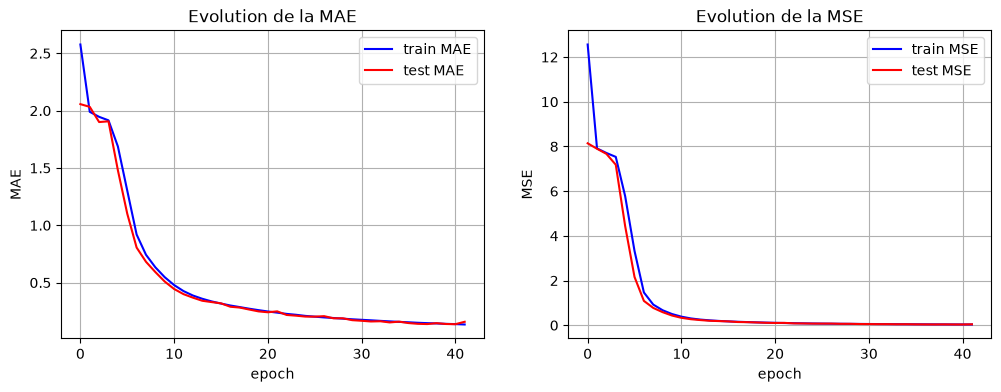

In [12]:
trainmae = history.history ["mae"]
testmae = history.history ["val_mae"]
trainmse = history.history ["loss"]
testmse = history.history ["val_loss"]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot (range (len (trainmae)), trainmae, "b", label = "train MAE")
axs[0].plot (range (len (testmae)), testmae, "r", label = "test MAE")
axs[0].set_title ("Evolution de la MAE")
axs[0].set_xlabel ("epoch")
axs[0].set_ylabel ("MAE")
axs[0].legend ()
axs[0].grid (True)


axs[1].plot (range (len (trainmse)), trainmse, "b", label = "train MSE")
axs[1].plot (range (len (testmse)), testmse, "r", label = "test MSE")
axs[1].set_title ("Evolution de la MSE")
axs[1].set_xlabel ("epoch")
axs[1].set_ylabel ("MSE")
axs[1].legend ()
axs[1].grid (True)
#fig.savefig(f"Courbes/3m{datetime.datetime.now().strftime('%H%M')}.png", dpi=300)

plt.show ()

## **6. Chargement du modèle**

In [13]:
network = models.load_model("deepmap.keras")

## **7. Validation du modèle**

In [14]:
%%time
start = time.time ()
a = network.predict (Xval)
end = time.time ()

a = a.reshape (len (Xval), 1784)

MAE = np.mean (abs (Yval - a))
MSE = np.mean ((Yval - a)**2)
r2 = r2_score(Yval, a)

print (f" ")
print (f" MAE du réseau : {MAE:.4f}")
print (f" MSE du réseau : {MSE:.4f}")
print(f" R² score du réseau : {r2:.4f}")
print (f" ")
print(f"Decoding time : {(end - start)*1000000/len (Xval):.3f} µs -----> trame de {Xval.shape[1]} bits")

150/150 ━━━━━━━━━━━━━━━━━━━━ 28s 185ms/step
 
 MAE du réseau : 0.1375
 MSE du réseau : 0.0334
 R² score du réseau : 0.9997
 
Decoding time : 5853.592 µs -----> trame de 1784 bits
CPU times: user 57.3 s, sys: 6.77 s, total: 1min 4s
Wall time: 28.2 s


## **8. Exemples**

In [16]:
print (f" ")
print (f" LLR prédits: ")
print (f" ")
print (a[5].round (2).reshape ((1784,)))
print (f" ")
print (f" LLR vérité : ")
print (f" ")
b = Yval[5].round (2)
print (b)

 
 LLR prédits: 
 
[ 9.34 10.7   4.19 ...  4.42 -6.67 -1.55]
 
 LLR vérité : 
 
[ 9.46 11.3   3.99 ...  4.8  -6.8  -1.43]
